In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import json
import zipfile

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
drive_folder = Path(
    "/content/drive/MyDrive/MMA3001_Project/dataset"
)

zip_files = list(drive_folder.glob("*.zip"))

print("Found ZIP files:")
for file in zip_files:
    print(file.name)

assert len(zip_files) == 1, (
    "Expected one ZIP file. Check the Drive folder."
)

dataset_folder = Path("/content/dataset")
dataset_folder.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_files[0], "r") as archive:
    for member in archive.infolist():
        destination = (
            dataset_folder / member.filename
        ).resolve()

        if not destination.is_relative_to(
            dataset_folder.resolve()
        ):
            raise ValueError("Unsafe ZIP path detected")

    archive.extractall(dataset_folder)

print("Dataset extracted.")

Found ZIP files:
Pork Rasher Error-Packaging-.v4i.coco.zip
Dataset extracted.


In [6]:
for path in list(dataset_folder.rglob("*"))[:40]:
    print(path.relative_to(dataset_folder))

train
README.roboflow.txt
README.dataset.txt
valid
test
train/frame_with_red_6254_jpg.rf.0a5f81664756fe834024404a58a51961.jpg
train/frame_with_red_5760_jpg.rf.f77f7b937c1d26157fd8205d36923737.jpg
train/frame_with_red_7990_jpg.rf.f24a2eddad13a9dc4a4558b219c4dea6.jpg
train/frame_with_red_4736_jpg.rf.42e6844d0de35d8651458f79792d0a96.jpg
train/frame_with_red_2924_jpg.rf.05d49ffee1a53ef791d4cbd70e7ec5bf.jpg
train/frame_with_red_4413_jpg.rf.10feb547f9cfb6adabbfaba1f946f7ef.jpg
train/frame_with_red_35_jpg.rf.d0d368275c13c051732e633e4efd14ad.jpg
train/frame_with_red_7243_jpg.rf.ad6d753caa508f0e918ca0916d1700ca.jpg
train/frame_with_red_6230_jpg.rf.638906a7a16d6ef6b034b9326223f0e7.jpg
train/frame_with_red_8242_jpg.rf.6224432d93f7c4cc4217e8d20d9edba3.jpg
train/frame_with_red_7241_jpg.rf.92d91a766d5cb8b4d7fc757a0a6d331b.jpg
train/frame_with_red_2562_jpg.rf.901c774f11d20539ae9f006bec8ff388.jpg
train/frame_with_red_8199_jpg.rf.6b3c6b2fc594bbc8241ca7d998086cad.jpg
train/frame_with_red_2186_jpg.rf.e1f

In [7]:
annotation_files = {
    path.parent.name: path
    for path in dataset_folder.rglob(
        "_annotations.coco.json"
    )
}

print(annotation_files)

assert all(
    split in annotation_files
    for split in ["train", "valid", "test"]
), "Missing one or more expected annotation files."

datasets = {}

for split, path in annotation_files.items():
    with open(path, "r") as file:
        datasets[split] = json.load(file)

{'train': PosixPath('/content/dataset/train/_annotations.coco.json'), 'valid': PosixPath('/content/dataset/valid/_annotations.coco.json'), 'test': PosixPath('/content/dataset/test/_annotations.coco.json')}


In [8]:
for category in datasets["train"]["categories"]:
    print(category["id"], category["name"])

0 packaging-error
1 loose-meat
2 packaging-error
3 twisted-meat
4 unsealed
5 wrinkle


In [9]:
summary = []

for split in ["train", "valid", "test"]:
    data = datasets[split]

    summary.append({
        "Split": split,
        "Images": len(data["images"]),
        "Annotations": len(data["annotations"])
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Split,Images,Annotations
0,train,3349,2923
1,valid,120,121
2,test,80,79


In [10]:
rows = []

for split in ["train", "valid", "test"]:
    data = datasets[split]

    categories = {
        item["id"]: item["name"]
        for item in data["categories"]
    }

    image_labels = defaultdict(set)

    for annotation in data["annotations"]:
        image_labels[annotation["image_id"]].add(
            categories[annotation["category_id"]]
        )

    for category_name in categories.values():
        positive_images = sum(
            category_name in image_labels[image["id"]]
            for image in data["images"]
        )

        rows.append({
            "Split": split,
            "Defect": category_name,
            "Positive images": positive_images,
            "Negative images": (
                len(data["images"]) - positive_images
            )
        })

distribution_df = pd.DataFrame(rows)

display(distribution_df)

,Split,Defect,Positive images,Negative images
0,train,packaging-error,1541,1808
1,train,loose-meat,66,3283
2,train,packaging-error,1541,1808
3,train,twisted-meat,69,3280
4,train,unsealed,1055,2294
5,train,wrinkle,18,3331
6,valid,packaging-error,23,97
7,valid,loose-meat,3,117
8,valid,packaging-error,23,97
9,valid,twisted-meat,3,117


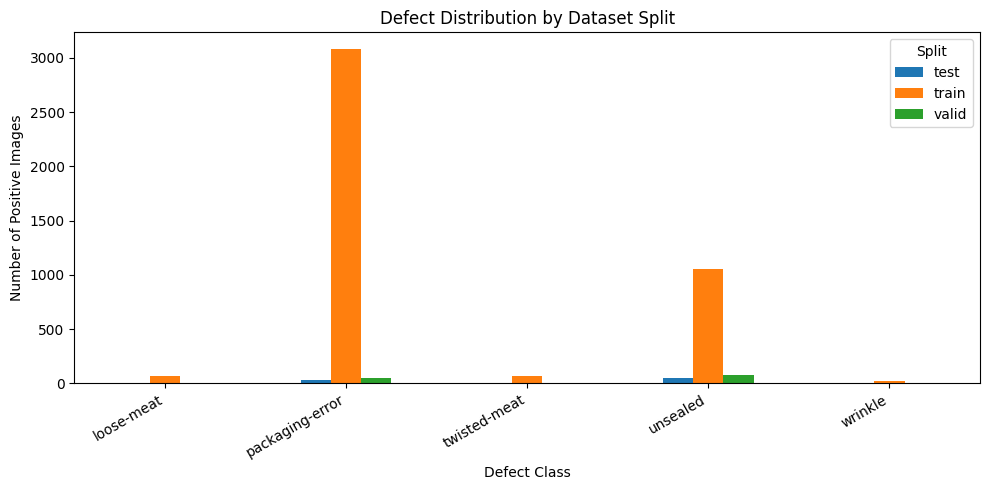

In [12]:
# Group by Split and Defect to sum up any duplicate categories
plot_data = distribution_df.groupby(["Defect", "Split"])["Positive images"].sum().unstack(fill_value=0)

plot_data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Defect Distribution by Dataset Split")
plt.ylabel("Number of Positive Images")
plt.xlabel("Defect Class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()